# Module 9 — Synthetic Control

Part of the Causal Inference Playbook. Course program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

- The question: did Proposition 99, a California tobacco law, cut the number of cigarettes sold in California?
- The problem: only one state passed the law. Comparing California after the law with California before the law mixes the law's effect with everything else that changed over those years, such as smoking falling across the whole US. Comparing California with other states mixes the law's effect with the ways the states differ.
- The way around: build a stand-in for California out of other states. The stand-in is a weighted mean of other states' cigarette sales, with weights chosen so that, in the years before the law, the stand-in's sales stay close to California's sales in every year. After the law, the stand-in's sales show what California's sales would have been without the law.
- How this module differs from the earlier modules: here a single state gets the law, and the comparison group is built from many states so that its sales before the law match California's sales, instead of taking an existing group and hoping that its sales moved like California's.
- The method: synthetic control. "Synthetic" means built, not observed: the stand-in for California is called synthetic California.
- The rule synthetic control needs, the no-other-change rule: after the law, nothing else that affects cigarette sales may change in California and not in the states that build synthetic California. The data can rule out some other changes, such as an unusual change in one of the states that build synthetic California, but not every change in California.

## From the curriculum

> ## <u>Module 9 — Synthetic Control</u>
>
> **Concepts**
> - Treated state: the one state a law covers. Here, California and its tobacco
>   law, Proposition 99.
> - Donor states: states without such a law, from which the stand-in for the
>   treated state is built. Here, 38 US states.
> - Synthetic control: a weighted mean of the donor states' sales. The weights
>   are 0 or more, add up to 1, and give the smallest gaps to the treated state's
>   sales before the law. After the law, gap = (treated state's sales) −
>   (synthetic control's sales) estimates the law's effect.
> - Size of the gap before the law: one number for how close the synthetic
>   control's sales stay to the treated state's sales before the law. A synthetic
>   control that doesn't stay close before the law can't stand in for the
>   treated state after the law.
> - Placebo states: the same calculation for each donor state, as if that state
>   had passed the law. Each state's ratio = (size of the gap after the law) ÷
>   (size of the gap before the law). If the law did nothing, the treated state
>   is one state among all of them, so the treated state's rank among all the
>   ratios shows how likely chance alone is to produce a ratio that high.
> - Leave-one-out: rebuild the synthetic control without each donor state that
>   has a weight, one state at a time. The estimate shouldn't rest on one state.
> - Fake law year: the same calculation with a law year at which nothing
>   happened, fitted only on the years before that fake year. A large gap after
>   the fake year would mean the method finds gaps that don't come from the law.
>
> **Why it matters**
> Many changes hit one unit only: a law in one state, a price change in one
> country, a launch in one city. No similar unit is left untouched for a plain
> comparison. Synthetic control builds the comparison from a mix of untouched
> units. The price: with one treated unit, chance is judged only by ranking it
> among the placebo units, and the number of units limits how small the chance
> of a gap that large with no law can get.
>
> **Worked example**
> Cigarette sales per person in 39 US states, 1970–2000, from a 2010 study by
> Alberto Abadie, Alexis Diamond and Jens Hainmueller. Synthetic California, its
> fit before 1989, the gap from 1989 to 2000, placebo states, leave-one-out,
> and a fake law year in 1980.
>
> **Resources**
> - [Causal Inference: The Mixtape, ch. 11 "Synthetic Control"](https://mixtape.scunning.com/11-synthetic_control)
>   (Scott Cunningham, ~90 min for section 11.1, verified): the method
>   ("Formalization"), the Proposition 99 example, and placebo states
>   ("Inference with Synthetic Control").
> - [The Effect, ch. 22 "A Gallery of Rogues: Other Methods"](https://theeffectbook.net/ch-TheEdge.html)
>   (Nick Huntington-Klein, ~20 min for section 22.2.1 "Synthetic Control",
>   verified): the method and placebo tests in short.
> - [A/B Testing Playbook, Module 8, Part 2](https://github.com/omri-sabag83/A-B-Testing-Playbook/blob/main/08_quasi_experiments.ipynb):
>   a shipping-fee change in 5 states compared with 5 similar states by
>   difference-in-differences, on made-up numbers. Synthetic control replaces
>   that comparison group when no group of untouched states moves like the
>   treated one.
>
> **Exercise type:** Virginia, a placebo state that ranked above California: its
> gap by hand, and what a ranking of 39 states can show at best. Fully worked.
>
> **Interview angle:** "A food-delivery app raised its delivery fee in one city
> only. Did the fee cut orders in that city?"

## The data

Cigarette sales in 39 US states, from 1970 to 2000, from the 2010 study by Alberto Abadie, Alexis Diamond and Jens Hainmueller. Each row is one state in one year. This module uses three of the file's columns:
- State.
- Year.
- Cigarette sales: packs of cigarettes sold per person in the state in that year, counted from the state's tobacco tax records.

Proposition 99: California's voters passed the law in November 1988, and the law took effect in January 1989. The law raised California's tax on cigarettes by 25 cents a pack and spent the money on anti-smoking campaigns. So 1970 to 1988 are the years before the law, and 1989 to 2000 are the years after the law.

Why 39 states and not 50: the study left out 11 states that started their own large tobacco programs, or raised their own cigarette tax by 50 cents a pack or more, between 1989 and 2000. The study also left out Washington, DC, which is not a state. The sales of those 11 states after 1988 include the effect of their own laws, so those states can't show what sales do without a law. The 38 states left besides California are the donor states: the states synthetic California is built from.

The output counts the states and years, and checks that every row has a sales value.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import nnls

import common

raw = pd.read_stata(common.RAW / "smoking.dta")
sales = (raw.assign(state=raw.state.astype(str), year=raw.year.astype(int), cigsale=raw.cigsale.astype(float).round(1))
         .pivot(index="year", columns="state", values="cigsale"))
donors = [state for state in sales.columns if state != "California"]
BEFORE, AFTER = list(range(1970, 1989)), list(range(1989, 2001))
CALIFORNIA_BLUE = "#1c5aa6"
print(f"States = {sales.shape[1]}: California and {len(donors)} donor states")
print(f"Years = {sales.index.min()} to {sales.index.max()} = {len(sales)} years")
print(f"  Before the law, 1970 to 1988 = {len(BEFORE)} years")
print(f"  After the law, 1989 to 2000 = {len(AFTER)} years")
print(f"Rows in the file = {sales.shape[1]} states x {len(sales)} years = {len(raw)}")
print(f"Rows with no cigarette sales = {raw.cigsale.isna().sum()}")

States = 39: California and 38 donor states
Years = 1970 to 2000 = 31 years
  Before the law, 1970 to 1988 = 19 years
  After the law, 1989 to 2000 = 12 years
Rows in the file = 39 states x 31 years = 1209
Rows with no cigarette sales = 0


## Did cigarette sales fall faster in California than in the other states after the law?

The simplest stand-in for California's sales without the law is the mean sales of the 38 donor states. Before calculating anything, the chart shows both. Look at two things: whether California's line falls faster than the 38-state mean after 1988, and whether the two lines moved alike before 1989, when no law acted on either.

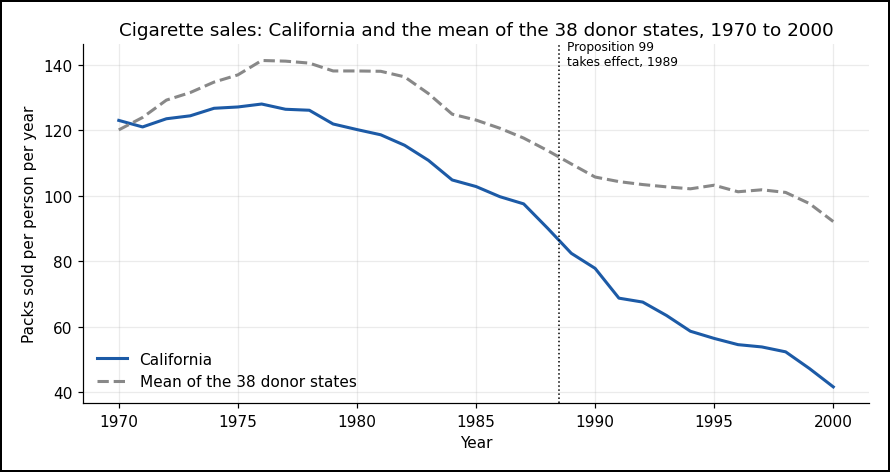

In [2]:
donor_mean = sales[donors].mean(axis=1).round(1)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(sales.index, sales.California, color=CALIFORNIA_BLUE, lw=2, label="California")
ax.plot(sales.index, donor_mean, color=common.GREY, lw=2, ls="--", label="Mean of the 38 donor states")
ax.axvline(1988.5, color="black", ls=":", lw=1)
ax.text(1988.8, 140, "Proposition 99\ntakes effect, 1989", fontsize=8)
ax.set_xlabel("Year")
ax.set_ylabel("Packs sold per person per year")
ax.set_title("Cigarette sales: California and the mean of the 38 donor states, 1970 to 2000")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

**Observation:** after 1988, California's sales fall faster than the 38-state mean. But California's sales were already falling faster before 1989: California started above the 38-state mean and ended 1988 far below the 38-state mean.

Before 1989, no law acted on California or on the donor states. If the 38-state mean moved like California's sales when no law acts, the gap between California and the 38-state mean would stay about the same in those years. The outputs measure the gap in the first year and in the last year before the law. The chart shows the years in between.

In [3]:
def mean_gap_in(year):
    total = round(sales.loc[year, donors].sum(), 1)
    print(f"Mean of the 38 donor states, {year}")
    print(f"  = (sum of the 38 states' sales) / 38 = {total:.1f} / 38 = {donor_mean[year]:.1f} packs per person")
    gap = round(sales.California[year] - donor_mean[year], 1)
    print(f"Gap, {year}")
    print("  = (California's sales) - (mean of the 38 donor states)")
    print(f"  = {sales.California[year]:.1f} - {donor_mean[year]:.1f} = {gap:.1f} packs per person")
    return gap

gap_1970 = mean_gap_in(1970)

Mean of the 38 donor states, 1970
  = (sum of the 38 states' sales) / 38 = 4563.2 / 38 = 120.1 packs per person
Gap, 1970
  = (California's sales) - (mean of the 38 donor states)
  = 123.0 - 120.1 = 2.9 packs per person


In [4]:
gap_1988 = mean_gap_in(1988)

Mean of the 38 donor states, 1988
  = (sum of the 38 states' sales) / 38 = 4325.3 / 38 = 113.8 packs per person
Gap, 1988
  = (California's sales) - (mean of the 38 donor states)
  = 90.1 - 113.8 = -23.7 packs per person


In [5]:
print("Change in the gap from 1970 to 1988")
print("  = (gap, 1988) - (gap, 1970)")
print(f"  = {gap_1988:.1f} - {gap_1970:.1f} = {gap_1988 - gap_1970:.1f} packs per person")

Change in the gap from 1970 to 1988
  = (gap, 1988) - (gap, 1970)
  = -23.7 - 2.9 = -26.6 packs per person


**Observation:** even before the law, California's sales fell faster than the 38-state mean. Suppose California's sales kept falling faster than the mean after the law, for the same old reasons. Comparing California with the 38-state mean after the law would count that extra fall as the law's effect, because the 38-state mean can't tell an old faster fall from a fall caused by the law.

**Conclusion:** the plain mean of the 38 donor states can't stand in for California.

## Can a mix of other states stand in for California?

The 38-state mean gives every donor state the same weight, 1 ÷ 38. Synthetic control gives each donor state its own weight instead:
- Synthetic California's sales in a year = (weight of state 1 × sales of state 1) + (weight of state 2 × sales of state 2) + … for all 38 donor states.
- Gap in a year = (California's sales) − (synthetic California's sales).

The weights follow three rules:
1. Each weight is 0 or more.
2. The weights add up to 1. With rules 1 and 2, synthetic California's sales in a year are an average of the weighted states' sales in that year, and an average can't be higher than the highest value or lower than the lowest value. So synthetic California's sales never go above the highest donor state or below the lowest donor state.
3. Among all weights that follow rules 1 and 2, the module uses the weights that give the smallest sum of squared gaps over the 19 years before the law. The gaps are squared so that positive gaps and negative gaps can't cancel out.

Rules 1 and 2 have a cost: if California's sales were above every donor state in some year, no mix could reach California's sales in that year. So the first output checks that California lies inside the donor states' range in every year before the law. Passing this check is needed but not enough: whether one set of weights stays close to California in all 19 years together shows only in the gaps below.

In [6]:
lowest, highest = sales.loc[BEFORE, donors].min(axis=1), sales.loc[BEFORE, donors].max(axis=1)
inside = ((sales.California[BEFORE] >= lowest) & (sales.California[BEFORE] <= highest)).sum()
print(f"Years before the law in which California's sales lie between the lowest and the highest donor state = {inside} of {len(BEFORE)}")
print(f"  Lowest donor state: {', '.join(sales.loc[BEFORE, donors].idxmin(axis=1).unique())} in every year")
print(f"  Highest donor state: {', '.join(sales.loc[BEFORE, donors].idxmax(axis=1).unique())} in every year")

Years before the law in which California's sales lie between the lowest and the highest donor state = 19 of 19
  Lowest donor state: Utah in every year
  Highest donor state: New Hampshire in every year


A fitting function, a standard least-squares solver, returns the weights that follow the three rules. The module uses only what the solver returns: the weights. Each weight is rounded to 3 decimals, and every synthetic number below is built from the rounded weights, so every number can be checked by hand. When rounded weights add up to slightly less or more than 1, the largest weight takes the difference, so the weights still add up to 1. California's rounded weights add up to exactly 1.

In [7]:
def fit_weights(target, pool, years=BEFORE):
    # Returns the weights of the states in `pool`: each 0 or more, adding up to 1, with the smallest sum of
    # squared gaps to `target` over `years`. nnls finds the states that get a weight, and an exact solve on
    # those states makes the weights add up to exactly 1.
    X, y = sales.loc[years, pool].to_numpy(), sales.loc[years, target].to_numpy()
    rough, _ = nnls(np.vstack([X, 1e5 * np.ones(len(pool))]), np.append(y, 1e5), maxiter=10000)
    keep = np.flatnonzero(rough > 1e-9)
    while True:
        XS = X[:, keep]
        system = np.block([[2 * XS.T @ XS, np.ones((len(keep), 1))], [np.ones((1, len(keep))), np.zeros((1, 1))]])
        solved = np.linalg.solve(system, np.append(2 * XS.T @ y, 1))[:-1]
        if (solved >= 0).all():
            break
        keep = keep[solved > 0]
    weights = pd.Series(0.0, index=pool)
    weights.iloc[keep] = solved
    weights = weights.round(3)
    weights[weights.idxmax()] = round(weights.max() + 1 - weights.sum(), 3)
    return weights[weights > 0].sort_values(ascending=False)

def build(target, weights):
    synthetic = (sales[list(weights.index)] * weights).sum(axis=1).round(2)
    return synthetic, (sales[target] - synthetic).round(2)

def size_of(gap, years):
    squared = round((gap[years] ** 2).round(4).sum(), 2)
    return squared, round((squared / len(years)) ** 0.5, 3)

weights = fit_weights("California", donors)
print("Weights of synthetic California (donor states with a weight above 0):")
common.show(pd.DataFrame({"Donor state": weights.index, "Weight": weights.map("{:.3f}".format).values}))
print(f"Sum of the weights = {' + '.join(f'{w:.3f}' for w in weights)} = {weights.sum():.3f}")
print(f"Donor states with weight 0 = {len(donors)} - {len(weights)} = {len(donors) - len(weights)}")

Weights of synthetic California (donor states with a weight above 0):
Donor state    Weight
Utah            0.394
Montana         0.232
Nevada          0.205
Connecticut     0.109
New Hampshire   0.045
Colorado        0.015
Sum of the weights = 0.394 + 0.232 + 0.205 + 0.109 + 0.045 + 0.015 = 1.000
Donor states with weight 0 = 38 - 6 = 32


**Observation:** six donor states get a weight above 0, and Utah gets the largest weight, 0.394. The other 32 donor states get a weight of 0. Utah has the lowest sales of all donor states, and from 1978 to 1988 California's sales sit below the sales of most donor states, so the mix needs a large weight on a low-selling state to come down to California's level in those years.

The table shows, for each year before the law, the six weighted states' sales, synthetic California's sales, California's sales, and the gap.

In [8]:
synthetic, gap = build("California", weights)

def year_table(target, weights, synthetic, gap, years):
    table = pd.DataFrame({"Year": [str(year) for year in years]})
    for state in weights.index:
        table[f"{state} ({weights[state]:.3f})"] = sales.loc[years, state].map("{:.1f}".format).values
    table[f"Synthetic {target}"] = synthetic[years].map("{:.2f}".format).values
    table[target] = sales.loc[years, target].map("{:.1f}".format).values
    table["Gap"] = gap[years].map("{:.2f}".format).values
    table["Gap²"] = (gap[years] ** 2).round(4).map("{:.4f}".format).values
    common.show(table)

print("California and synthetic California before the law, 1970 to 1988 (each state's weight in brackets):")
print()
year_table("California", weights, synthetic, gap, BEFORE)

California and synthetic California before the law, 1970 to 1988 (each state's weight in brackets):

Year  Utah (0.394)  Montana (0.232)  Nevada (0.205)  Connecticut (0.109)  New Hampshire (0.045)  Colorado (0.015)  Synthetic California  California    Gap     Gap²
1970          65.5            111.2           189.5                120.0                  265.7             124.8                117.36       123.0   5.64  31.8096
1971          67.7            115.6           190.5                117.6                  278.0             125.5                119.76       121.0   1.24   1.5376
1972          71.3            122.2           198.6                110.8                  296.2             134.3                124.58       123.5  -1.08   1.1664
1973          72.7            119.9           201.5                109.3                  279.0             137.9                124.31       124.4   0.09   0.0081
1974          75.6            121.9           204.7                112.4       

Synthetic California's sales in one year, calculated in full, so the rest of the column can be checked the same way:

In [9]:
def by_hand(target, weights, synthetic, gap, year):
    print(f"Synthetic {target}, {year}")
    print(f"  = (weight x sales), added over the {len(weights)} weighted states")
    print("  = " + " + ".join(f"({weights[state]:.3f} x {sales.loc[year, state]:.1f})" for state in weights.index))
    print("  = " + " + ".join(f"{weights[state] * sales.loc[year, state]:.4f}" for state in weights.index))
    print(f"  = {synthetic[year]:.2f} packs per person, rounded to two decimals")
    print(f"Gap, {year}")
    print(f"  = ({target}'s sales) - (synthetic {target}'s sales)")
    print(f"  = {sales.loc[year, target]:.1f} - {synthetic[year]:.2f} = {gap[year]:.2f} packs per person")

by_hand("California", weights, synthetic, gap, 1988)

Synthetic California, 1988
  = (weight x sales), added over the 6 weighted states
  = (0.394 x 55.0) + (0.232 x 87.1) + (0.205 x 141.9) + (0.109 x 104.8) + (0.045 x 180.4) + (0.015 x 94.6)
  = 21.6700 + 20.2072 + 29.0895 + 11.4232 + 8.1180 + 1.4190
  = 91.93 packs per person, rounded to two decimals
Gap, 1988
  = (California's sales) - (synthetic California's sales)
  = 90.1 - 91.93 = -1.83 packs per person


To put the 19 gaps before the law into one number, the size of the gap before the law = square root of [(sum of squared gaps, 1970 to 1988) ÷ 19]. The squares stop positive and negative gaps from cancelling out, and the square root brings the number back to packs per person.

In [10]:
squared_before, size_before = size_of(gap, BEFORE)
print("Size of the gap before the law, California")
print("  = square root of [(sum of squared gaps, 1970 to 1988) / 19]")
print(f"  = square root of ({squared_before:.2f} / 19) = {size_before:.3f} packs per person")

Size of the gap before the law, California
  = square root of [(sum of squared gaps, 1970 to 1988) / 19]
  = square root of (52.18 / 19) = 1.657 packs per person


To judge whether 1.657 is small, the output calculates the same size for the plain 38-state mean, the stand-in that failed in the section *Did cigarette sales fall faster in California than in the other states after the law?*, with all 19 of its gaps. There is no standard cutoff for a small size: this module calls synthetic California close when its size is far below the plain mean's size.

In [11]:
mean_gap_series = (sales.California - donor_mean).round(1)
mean_squared, mean_size = size_of(mean_gap_series, BEFORE)
print("California and the plain mean of the 38 donor states, 1970 to 1988:")
common.show(pd.DataFrame({"Year": [str(year) for year in BEFORE], "Mean of 38 states": donor_mean[BEFORE].map("{:.1f}".format).values,
                          "California": sales.California[BEFORE].map("{:.1f}".format).values,
                          "Gap": mean_gap_series[BEFORE].map("{:.1f}".format).values,
                          "Gap²": (mean_gap_series[BEFORE] ** 2).round(4).map("{:.2f}".format).values}))
print()
print("Size of the gap before the law, plain mean of the 38 donor states")
print("  = square root of [(sum of squared gaps, 1970 to 1988) / 19]")
print(f"  = square root of ({mean_squared:.2f} / 19) = {mean_size:.3f} packs per person")
print()
print("Ratio of the two sizes = (size, 38-state mean) / (size, synthetic California)")
print(f"  = {mean_size:.3f} / {size_before:.3f} = {mean_size / size_before:.1f}")

California and the plain mean of the 38 donor states, 1970 to 1988:
Year  Mean of 38 states  California    Gap    Gap²
1970              120.1       123.0    2.9    8.41
1971              123.9       121.0   -2.9    8.41
1972              129.2       123.5   -5.7   32.49
1973              131.5       124.4   -7.1   50.41
1974              134.7       126.7   -8.0   64.00
1975              136.9       127.1   -9.8   96.04
1976              141.3       128.0  -13.3  176.89
1977              141.1       126.4  -14.7  216.09
1978              140.5       126.1  -14.4  207.36
1979              138.1       121.9  -16.2  262.44
1980              138.1       120.2  -17.9  320.41
1981              138.0       118.6  -19.4  376.36
1982              136.3       115.4  -20.9  436.81
1983              131.2       110.8  -20.4  416.16
1984              124.9       104.8  -20.1  404.01
1985              123.1       102.8  -20.3  412.09
1986              120.6        99.7  -20.9  436.81
1987          

**Observation:** before the law, the size of synthetic California's gap is 1.657 packs per person, 9.7 times smaller than the 38-state mean's 16.044. So the weights did what equal weights couldn't: synthetic California stays close to California's sales before the law.

The chart shows California and synthetic California over all 31 years. Look for the dashed line near the solid line before 1989, and the space between the two lines after 1988.

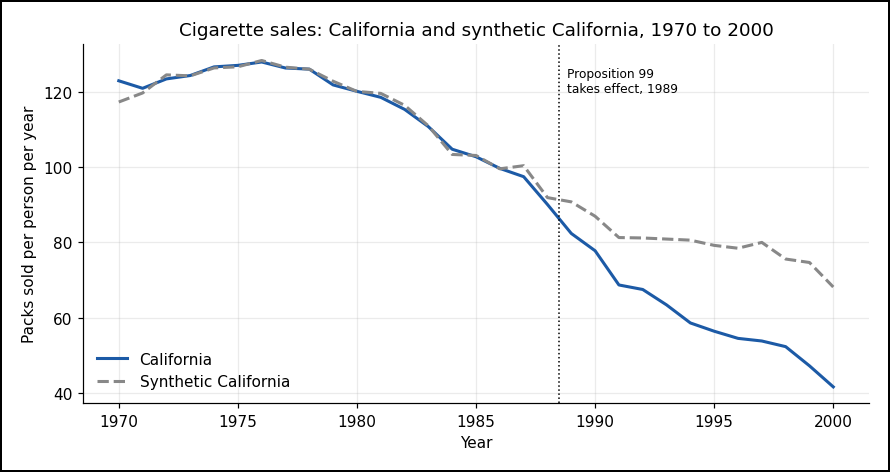

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(sales.index, sales.California, color=CALIFORNIA_BLUE, lw=2, label="California")
ax.plot(sales.index, synthetic, color=common.GREY, lw=2, ls="--", label="Synthetic California")
ax.axvline(1988.5, color="black", ls=":", lw=1)
ax.text(1988.8, 120, "Proposition 99\ntakes effect, 1989", fontsize=8)
ax.set_xlabel("Year")
ax.set_ylabel("Packs sold per person per year")
ax.set_title("Cigarette sales: California and synthetic California, 1970 to 2000")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

**Conclusion:** synthetic California stays close to California's sales before the law, so synthetic California can stand in for California after the law, if the no-other-change rule holds.

## How big is the gap after the law?

After 1988, synthetic California's sales show what California's sales would have been without the law, if the no-other-change rule holds. Each year's gap is the estimate of the law's effect in that year. The table uses the same weights as before the law.

In [13]:
print("California and synthetic California after the law, 1989 to 2000 (each state's weight in brackets):")
print()
year_table("California", weights, synthetic, gap, AFTER)

California and synthetic California after the law, 1989 to 2000 (each state's weight in brackets):

Year  Utah (0.394)  Montana (0.232)  Nevada (0.205)  Connecticut (0.109)  New Hampshire (0.045)  Colorado (0.015)  Synthetic California  California     Gap      Gap²
1989          57.0             86.2           137.9                100.6                  172.9              88.8                 90.80        82.4   -8.40   70.5600
1990          53.4             84.7           137.3                 91.5                  152.4              87.4                 86.98        77.8   -9.18   84.2724
1991          53.5             82.9           115.5                 86.7                  144.8              90.2                 81.31        68.7  -12.61  159.0121
1992          55.0             86.6           110.0                 83.5                  143.7              88.3                 81.20        67.5  -13.70  187.6900
1993          56.2             86.0           108.1                 79

One number for the whole period: the mean gap after the law = (sum of the 12 gaps, 1989 to 2000) ÷ 12.

In [14]:
gap_sum = round(gap[AFTER].sum(), 2)
mean_gap = round(gap_sum / 12, 2)
print("Mean gap after the law, California")
print("  = (sum of the 12 gaps, 1989 to 2000) / 12")
print(f"  = {gap_sum:.2f} / 12 = {mean_gap:.2f} packs per person per year")

Mean gap after the law, California
  = (sum of the 12 gaps, 1989 to 2000) / 12
  = -233.78 / 12 = -19.48 packs per person per year


To show the mean gap as a share of the sales California would have had without the law, the output also gives the change in percent = (mean gap after the law) ÷ (mean of synthetic California's sales, 1989 to 2000).

In [15]:
synthetic_sum = round(synthetic[AFTER].sum(), 2)
synthetic_mean = round(synthetic_sum / 12, 2)
print("Mean of synthetic California's sales after the law")
print("  = (sum of synthetic California's sales, 1989 to 2000) / 12")
print(f"  = {synthetic_sum:.2f} / 12 = {synthetic_mean:.2f} packs per person per year")
print()
print("Change in percent, California")
print("  = (mean gap after the law) / (mean of synthetic California's sales after the law)")
print(f"  = {mean_gap:.2f} / {synthetic_mean:.2f} = {mean_gap / synthetic_mean:.1%}")

Mean of synthetic California's sales after the law
  = (sum of synthetic California's sales, 1989 to 2000) / 12
  = 957.98 / 12 = 79.83 packs per person per year

Change in percent, California
  = (mean gap after the law) / (mean of synthetic California's sales after the law)
  = -19.48 / 79.83 = -24.4%


**Observation:** the gap grows from (−8.40) packs per person in 1989 to (−26.56) in 2000. Over 1989 to 2000, California's sales are 19.48 packs per person per year below synthetic California's sales, on average, a mean gap of (−19.48). That is 24.4% below synthetic California's mean sales.

## Could chance alone produce a gap this large?

Synthetic California doesn't follow California perfectly even before the law: the size of the gap before the law is 1.657, not 0. So some gap after the law would appear with no law at all. The question is whether a gap as large as California's appears in states that passed no law.

A standard error needs many treated units whose gaps differ by chance, so that the spread of those gaps shows how much chance moves a gap. With one treated state there is one gap per year and no spread to measure. Instead, the test repeats the whole calculation for each donor state, as if that donor state had passed the law. These are placebo states:
- Each placebo state gets its own synthetic version, built from the other 37 donor states, with weights that follow the same three rules over 1970 to 1988.
- California is left out of every placebo state's donors, because California's sales after 1988 include the law.

A placebo state that synthetic control can't follow before the law gets large gaps after the law too, from the poor fit, not from a law. So each state's gap after the law is measured against the state's own gap before the law:
- Size of the gap after the law = square root of [(sum of squared gaps, 1989 to 2000) ÷ 12], built like the size before the law.
- Ratio = (size of the gap after the law) ÷ (size of the gap before the law).

If the law did nothing, California is one more state with no law, and nothing makes California's ratio more likely than any other state's ratio to land at a given place in the ranking of the 39 ratios. So California has the same chance, 1 in 39, of landing at each place. If California ranks 3rd, 3 of the 39 places (1st, 2nd and 3rd) are as high as California's or higher, so the chance of a place that high with no law = 3 ÷ 39. In general, the chance = (California's rank) ÷ 39. We want that chance at 5% or below, the usual rule for "chance alone is unlikely": a small chance means a ratio as high as California's rarely appears without a law.

California's ratio first, from the Gap² column of the table after the law:

In [16]:
squared_after, size_after = size_of(gap, AFTER)
ratio = round(size_after / size_before, 2)
print("Size of the gap after the law, California")
print("  = square root of [(sum of squared gaps, 1989 to 2000) / 12]")
print(f"  = square root of ({squared_after:.2f} / 12) = {size_after:.3f} packs per person")
print()
print("Ratio, California")
print("  = (size of the gap after the law) / (size of the gap before the law)")
print(f"  = {size_after:.3f} / {size_before:.3f} = {ratio:.2f}")

Size of the gap after the law, California
  = square root of [(sum of squared gaps, 1989 to 2000) / 12]
  = square root of (5079.75 / 12) = 20.575 packs per person

Ratio, California
  = (size of the gap after the law) / (size of the gap before the law)
  = 20.575 / 1.657 = 12.42


For 20 of the 38 placebo states, the rounded weights add up to 0.998, 0.999, 1.001 or 1.002 before the largest weight takes the difference. The appendix shows every placebo state's weights and calculation.

In [17]:
PLACEBO = {"California": (weights, gap, squared_before, size_before, squared_after, size_after, ratio)}
for state in donors:
    pool = [other for other in donors if other != state]
    state_weights = fit_weights(state, pool)
    _, state_gap = build(state, state_weights)
    state_before, state_size_before = size_of(state_gap, BEFORE)
    state_after, state_size_after = size_of(state_gap, AFTER)
    PLACEBO[state] = (state_weights, state_gap, state_before, state_size_before, state_after, state_size_after,
                      round(state_size_after / state_size_before, 2))
ranking = sorted(PLACEBO, key=lambda state: -PLACEBO[state][6])
print("All 39 states, ranked by ratio:")
print()
common.show(pd.DataFrame({"Rank": [str(r) for r in range(1, 40)], "State": ranking,
                          "Size before": [f"{PLACEBO[s][3]:.3f}" for s in ranking],
                          "Size after": [f"{PLACEBO[s][5]:.3f}" for s in ranking],
                          "Ratio": [f"{PLACEBO[s][6]:.2f}" for s in ranking],
                          "Mean gap after": [f"{round(PLACEBO[s][1][AFTER].sum(), 2) / 12:.2f}" for s in ranking]}))

All 39 states, ranked by ratio:

Rank  State           Size before  Size after  Ratio  Mean gap after
   1  Missouri              0.439      10.450  23.80            9.01
   2  Virginia              0.816      16.187  19.84          -15.55
   3  California            1.657      20.575  12.42          -19.48
   4  Georgia               1.094       9.923   9.07           -8.83
   5  Texas                 1.917      15.698   8.19          -14.20
   6  Oklahoma              1.962      15.916   8.11            7.38
   7  South Dakota          1.130       8.110   7.18            6.93
   8  Rhode Island          3.793      26.589   7.01          -25.49
   9  Nebraska              0.897       6.282   7.00            5.84
  10  Wisconsin             1.307       7.935   6.07            7.63
  11  Vermont               2.584      15.617   6.04           -9.86
  12  Louisiana             0.990       5.500   5.56            3.83
  13  West Virginia         2.536      14.018   5.53           11.94
 

In [18]:
rank = ranking.index("California") + 1
print("Chance of a ratio as high as California's, or higher, with no law")
print("  = (number of places as high as California's or higher) / (number of states in the ranking)")
print("  = (California's rank) / 39")
print(f"  = {rank} / 39 = {rank / 39:.1%}")

Chance of a ratio as high as California's, or higher, with no law
  = (number of places as high as California's or higher) / (number of states in the ranking)
  = (California's rank) / 39
  = 3 / 39 = 7.7%


The chart shows the same ranking, one bar per state, California in blue, so the distance between California and the two states above it, and the states below it, shows at a glance.

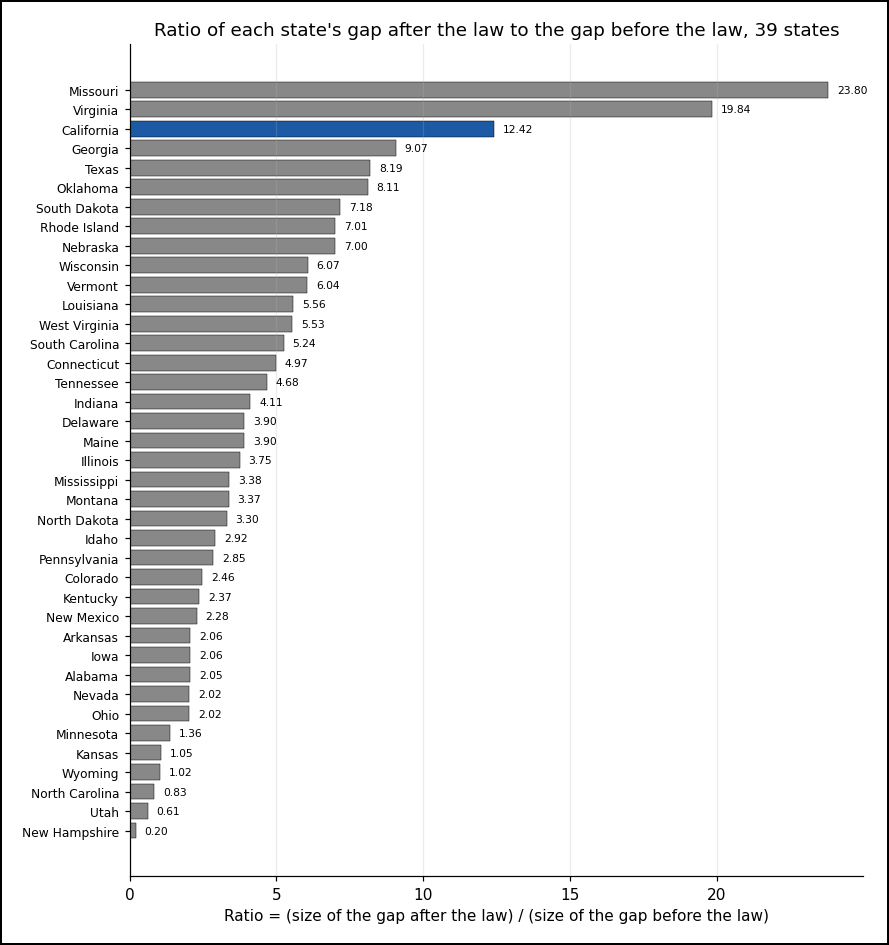

In [19]:
fig, ax = plt.subplots(figsize=(8, 8.5))
order = ranking[::-1]
ax.barh(order, [PLACEBO[s][6] for s in order], color=[CALIFORNIA_BLUE if s == "California" else common.GREY for s in order], edgecolor="black", linewidth=0.3)
for y, s in enumerate(order):
    ax.text(PLACEBO[s][6] + 0.3, y, f"{PLACEBO[s][6]:.2f}", va="center", fontsize=7)
ax.set_xlabel("Ratio = (size of the gap after the law) / (size of the gap before the law)")
ax.set_title("Ratio of each state's gap after the law to the gap before the law, 39 states")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Observation:** California's ratio, 12.42, ranks 3rd of 39. The chance of a ratio this high or higher with no law is 3 ÷ 39 = 7.7%, above the 5% we want. Two states that passed no law rank above California:
- Missouri, ratio 23.80: Missouri's mean gap after the law is above 0 (9.01), so Missouri sold more than synthetic Missouri. The ratio is built from squared gaps, so a gap above 0 and a gap below 0 count alike. A law that cuts sales gives a mean gap below 0. A test that counts a state above California only when the state's mean gap after the law is below 0 drops Missouri from the places above California, so California's place becomes 2nd. All 39 states stay in the ranking, so the chance = 2 ÷ 39 = 5.1%, still above 5%.
- Virginia, ratio 19.84: Virginia's mean gap after the law is (−15.55), so Virginia sold less than synthetic Virginia, with no law like Proposition 99.

Utah and New Hampshire are the lowest and the highest donor states in every year, so no mix of the other states can reach their sales. Their sizes of the gap before the law are the largest, 24.367 and 58.621, and dividing by those sizes puts the two states at the bottom of the ranking, so their poor fit doesn't count as a large gap.

The 2010 study built synthetic California from more columns than sales, such as the price of cigarettes and income, and in the study's version California ranked 1st of 39 (reported in the Mixtape's chapter 11, section "Inference with Synthetic Control", listed in the curriculum above). This module matches on sales alone, so that every number can be checked by hand from one column, and so the weights and the ranking differ from the study's. Neither ranking is the single right one: each ranking holds for its own way of building synthetic California, and the module's conclusions rest on the numbers calculated here.

**Conclusion:** by the usual 5% rule, the placebo states alone can't rule out chance as the source of California's gap, although almost every state without the law shows a smaller ratio.

## Does the gap rest on one donor state?

Synthetic California is built from six donor states, and Utah alone carries a weight of 0.394. If something unusual happened in one of the six states after 1988, synthetic California would carry that change into every gap after the law.

One example: Nevada borders California. If Californians drove to Nevada to buy cheaper cigarettes after California's tax rose, Nevada's sales would rise, synthetic California's sales would rise with Nevada's weight of 0.205, and the gap would become more negative without anyone smoking less.

Leave-one-out: rebuild synthetic California six times, each time without one of the six weighted states, with weights that follow the same three rules. What we want: in every rebuild, a mean gap after the law below 0, and a small move = (rebuild's mean gap) − (−19.48). The output ends on the largest move as a share of (−19.48). The table also shows each rebuild's size of the gap before the law, to check that every rebuild still stays close to California before the law. The appendix shows each rebuild's weights and full yearly table.

In [20]:
LEAVE_OUT = {}
for state in weights.index:
    pool = [other for other in donors if other != state]
    out_weights = fit_weights("California", pool)
    out_synthetic, out_gap = build("California", out_weights)
    LEAVE_OUT[state] = (out_weights, out_synthetic, out_gap, *size_of(out_gap, BEFORE), round(out_gap[AFTER].sum(), 2))
rows = []
for state, (out_weights, _, _, _, out_size, out_sum) in LEAVE_OUT.items():
    out_mean = round(out_sum / 12, 2)
    rows.append({"Left out": state,
                 "Size before": f"{out_size:.3f}", "Mean gap after = (sum of 12 gaps) / 12": f"{out_sum:.2f} / 12 = {out_mean:.2f}",
                 "Move = mean gap - (-19.48)": f"{out_mean - mean_gap:.2f}"})
print(f"Synthetic California, all six weighted states: size before = {size_before:.3f}, mean gap after = {gap_sum:.2f} / 12 = {mean_gap:.2f}")
print()
print("Synthetic California rebuilt without one weighted state:")
print()
common.show(pd.DataFrame(rows).astype(str))
largest_move = max(abs(round(out_sum / 12, 2) - mean_gap) for *_, out_sum in LEAVE_OUT.values())
print()
print("Largest move as a share of the mean gap")
print(f"  = (largest move, ignoring the sign) / (mean gap, ignoring the sign) = {largest_move:.2f} / {abs(mean_gap):.2f} = {largest_move / abs(mean_gap):.1%}")

Synthetic California, all six weighted states: size before = 1.657, mean gap after = -233.78 / 12 = -19.48

Synthetic California rebuilt without one weighted state:

Left out       Size before  Mean gap after = (sum of 12 gaps) / 12  Move = mean gap - (-19.48)
Utah                 2.376  -229.81 / 12 = -19.15                                         0.33
Montana              1.765  -215.04 / 12 = -17.92                                         1.56
Nevada               2.218  -230.03 / 12 = -19.17                                         0.31
Connecticut          1.814  -247.16 / 12 = -20.60                                        -1.12
New Hampshire        1.698  -237.03 / 12 = -19.75                                        -0.27
Colorado             1.658  -235.08 / 12 = -19.59                                        -0.11

Largest move as a share of the mean gap
  = (largest move, ignoring the sign) / (mean gap, ignoring the sign) = 1.56 / 19.48 = 8.0%


The chart shows California, synthetic California, and the six rebuilds. Look for the six orange lines staying near the thick dashed grey line after 1989, far above California's line.

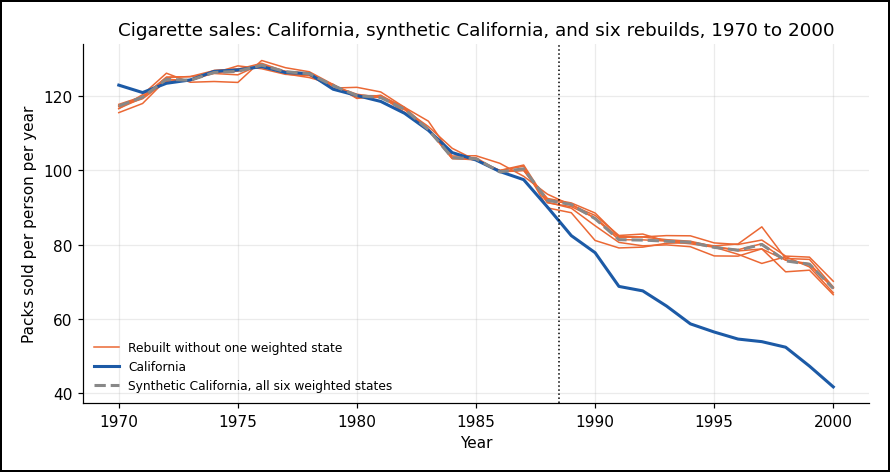

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for number, (state, (_, out_synthetic, _, _, _, _)) in enumerate(LEAVE_OUT.items()):
    ax.plot(sales.index, out_synthetic, color=common.ORANGE, lw=1, label="Rebuilt without one weighted state" if number == 0 else None)
ax.plot(sales.index, sales.California, color=CALIFORNIA_BLUE, lw=2, label="California")
ax.plot(sales.index, synthetic, color=common.GREY, lw=2, ls="--", label="Synthetic California, all six weighted states")
ax.axvline(1988.5, color="black", ls=":", lw=1)
ax.set_xlabel("Year")
ax.set_ylabel("Packs sold per person per year")
ax.set_title("Cigarette sales: California, synthetic California, and six rebuilds, 1970 to 2000")
ax.legend(frameon=False, loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

**Observation:** every rebuild gives a mean gap after the law below 0, from (−20.60) without Connecticut to (−17.92) without Montana, as we want. The largest move, 1.56 packs per person, is 8.0% of the mean gap. Every rebuild's size of the gap before the law, at most 2.376, stays far below the plain mean's 16.044. Like every other rebuild, without Nevada, the mean gap barely moves, to (−19.17), so buying across the border in Nevada doesn't explain the gap. Without Utah, the largest weight, synthetic California stays less close to California before the law (size 2.376 against 1.657), yet the mean gap after the law barely moves, to (−19.15).

**Conclusion:** the gap after the law doesn't rest on any one donor state.

## Does the method find a gap where no law passed?

Nothing about Proposition 99 happened in 1980. If synthetic California, built only from the years before 1980, shows a large gap from 1980 to 1988, the method finds gaps that don't come from the law, and the gap after 1989 could hold a gap that doesn't come from the law too. This is a fake law year.

The test pretends the law took effect in 1980, which splits the 19 years before the real law into 10 years to fit, 1970 to 1979, and 9 years to test, 1980 to 1988:
- The weights follow the same three rules, with the smallest sum of squared gaps over 1970 to 1979 only, 10 years.
- The gaps from 1980 to 1988, 9 years, play the part of the gaps after the law. All 9 years are before the real law, so none of those gaps comes from Proposition 99.

The weights make the gaps from 1970 to 1979 as small as possible, and the largest of those gaps still shows how far synthetic California misses California with no law at all. What we want: no gap from 1980 to 1988 larger than that largest gap, ignoring the sign. A larger gap is more than the method's usual miss.

In [22]:
FAKE_FIT, FAKE_AFTER = list(range(1970, 1980)), list(range(1980, 1989))
fake_weights = fit_weights("California", donors, FAKE_FIT)
print("Weights of synthetic California, fitted on 1970 to 1979 only (donor states with a weight above 0):")
print()
common.show(pd.DataFrame({"Donor state": fake_weights.index, "Weight": fake_weights.map("{:.3f}".format).values}))
print(f"Sum of the weights = {' + '.join(f'{w:.3f}' for w in fake_weights)} = {fake_weights.sum():.3f}")

Weights of synthetic California, fitted on 1970 to 1979 only (donor states with a weight above 0):

Donor state    Weight
Connecticut     0.330
Utah            0.323
Nevada          0.283
West Virginia   0.064
Sum of the weights = 0.330 + 0.323 + 0.283 + 0.064 = 1.000


In [23]:
fake_synthetic, fake_gap = build("California", fake_weights)
print("California and synthetic California fitted on 1970 to 1979, years 1970 to 1988 (each state's weight in brackets):")
print()
year_table("California", fake_weights, fake_synthetic, fake_gap, FAKE_FIT + FAKE_AFTER)

California and synthetic California fitted on 1970 to 1979, years 1970 to 1988 (each state's weight in brackets):

Year  Connecticut (0.330)  Utah (0.323)  Nevada (0.283)  West Virginia (0.064)  Synthetic California  California    Gap     Gap²
1970                120.0          65.5           189.5                  114.5                121.71       123.0   1.29   1.6641
1971                117.6          67.7           190.5                  111.5                121.72       121.0  -0.72   0.5184
1972                110.8          71.3           198.6                  117.5                123.32       123.5   0.18   0.0324
1973                109.3          72.7           201.5                  116.6                124.04       124.4   0.36   0.1296
1974                112.4          75.6           204.7                  119.9                127.11       126.7  -0.41   0.1681
1975                110.2          75.8           205.2                  123.2                126.81       127.

In [24]:
largest = fake_gap[FAKE_FIT].abs().max()
larger = [year for year in FAKE_AFTER if abs(fake_gap[year]) > largest]
print("Largest gap from 1970 to 1979, ignoring the sign")
print(f"  = {largest:.2f} packs per person, in {fake_gap[FAKE_FIT].abs().idxmax()}")
print(f"Years from 1980 to 1988 with a gap larger than {largest:.2f}, ignoring the sign = {len(larger)} of 9:")
for year in larger:
    print(f"  {year}: gap = {fake_gap[year]:.2f}")

Largest gap from 1970 to 1979, ignoring the sign
  = 2.08 packs per person, in 1979
Years from 1980 to 1988 with a gap larger than 2.08, ignoring the sign = 4 of 9:
  1985: gap = -3.81
  1986: gap = -4.44
  1987: gap = -9.02
  1988: gap = -9.39


The chart shows California and the synthetic California fitted on 1970 to 1979, with the fake law year and the real law year marked.

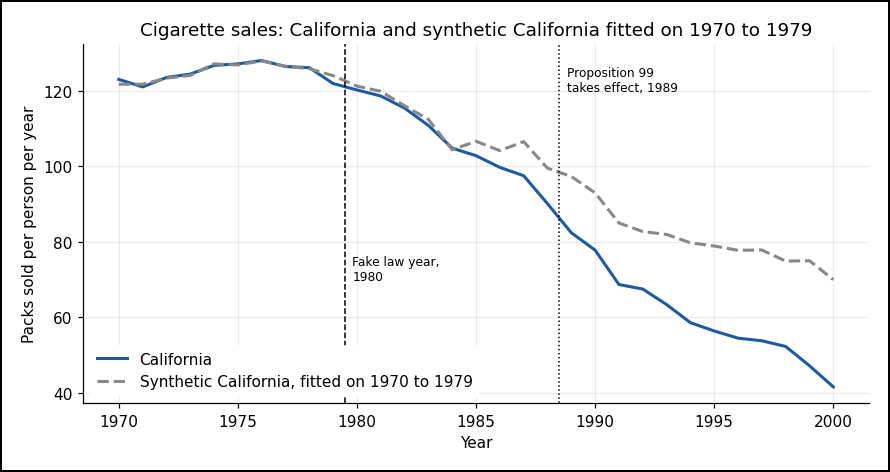

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(sales.index, sales.California, color=CALIFORNIA_BLUE, lw=2, label="California")
ax.plot(sales.index, fake_synthetic, color=common.GREY, lw=2, ls="--", label="Synthetic California, fitted on 1970 to 1979")
ax.axvline(1979.5, color="black", ls="--", lw=1)
ax.text(1979.8, 70, "Fake law year,\n1980", fontsize=8)
ax.axvline(1988.5, color="black", ls=":", lw=1)
ax.text(1988.8, 120, "Proposition 99\ntakes effect, 1989", fontsize=8)
ax.set_xlabel("Year")
ax.set_ylabel("Packs sold per person per year")
ax.set_title("Cigarette sales: California and synthetic California fitted on 1970 to 1979")
ax.legend(loc="lower left", framealpha=1, edgecolor="white")
plt.tight_layout()
plt.show()

**Observation:** the largest gap from 1970 to 1979 is 2.08 packs per person. From 1980 to 1984, every gap is smaller than 2.08, as we want: from (−1.60) to 0.44. From 1985 to 1988, all four gaps are larger than 2.08: (−3.81), (−4.44), (−9.02) and (−9.39). California's sales fell below synthetic California's sales from 1985 on, four years before the law.

The gaps from 1985 on have two possible sources, and the data can't tell them apart:
1. Something other than the law cut California's sales from 1985 on, before the law.
2. With only 10 years to match, a mix of states can match California's sales in those years without sharing California's later path. Each extra year is one more year in which the same weights must match California's sales, so with 19 years to match, as in the main synthetic California, such a chance match is harder, but still possible.

**Conclusion:** the method found a fall in years with no law, so part of the gap after the law may not come from Proposition 99, and the law's true effect is likely smaller than the gap shows.

## Is anything other than Proposition 99 behind the gap?

The no-other-change rule can't be proved, because we can't see everything that changed in California or in the donor states after 1988. Four points show what the data covers and what the data doesn't cover:

1. Laws in other states: the study left out every state with its own large tobacco program or large tax rise. Smaller tax rises in donor states remain. A smaller tax rise lowers that donor state's sales, which lowers synthetic California's sales, which makes the gap less negative, so smaller tax rises would make the gap too small, not too large.
2. Changes in one donor state: the leave-one-out check shows that no single weighted state drives the gap.
3. Changes in California before the law: the fake law year shows California's sales falling below synthetic California's sales from 1985 on. If something real began in California then, that change may continue after 1988 and sit inside the gap.
4. Sales are not smoking: the file counts packs sold in California. A Californian who buys cigarettes in another state lowers California's sales without smoking less. The file can't show packs bought outside California, so the fall in smoking may be smaller than the fall in sales.

Anything else that changed in California only, after 1988, and cut cigarette sales would show in the gap exactly like the law, and the data can't rule out such a change.

The answer to the module's question: California's cigarette sales fell far below synthetic California's sales after Proposition 99, and no single donor state drives that fall. But chance can't be ruled out by the usual 5% rule, and the fake law year failed. So the law probably cut sales, because California's ratio is higher than the ratio of almost every state without the law, and the fall doesn't rest on any one donor state. But the estimate of the fall may include part of a fall that began before the law, or the fake law year may have failed only because 10 years are too few to fit the weights, and the data can't tell which.

## Exercise — Virginia, a placebo state that ranked above California

Virginia passed no law like Proposition 99, yet Virginia's ratio ranked 2nd of 39, above California's. The exercise rebuilds Virginia's gap in 2000, the last year of the data, by hand, to show that a state with no law can show a gap of many packs per person below 0 in a single year. The calculation repeats the 1988 calculation of the section *Can a mix of other states stand in for California?*. The exercise then asks what a ranking of 39 states can show at best.

The output gives synthetic Virginia's weights, the weighted states' sales in 2000, and Virginia's sales in 2000.

Write your answers first, then read the answers below.

In [26]:
virginia_weights = PLACEBO["Virginia"][0]
print("Synthetic Virginia, weights and sales in 2000:")
print()
common.show(pd.DataFrame({"Donor state": virginia_weights.index, "Weight": virginia_weights.map("{:.3f}".format).values,
                          "Sales, 2000": sales.loc[2000, virginia_weights.index].map("{:.1f}".format).values}))
print(f"Virginia's sales, 2000 = {sales.loc[2000, 'Virginia']:.1f} packs per person")

Synthetic Virginia, weights and sales in 2000:

Donor state     Weight  Sales, 2000
Tennessee        0.271        108.7
Kentucky         0.209        156.2
West Virginia    0.108        107.9
Pennsylvania     0.092         87.9
North Carolina   0.092        109.0
Indiana          0.087        125.5
Iowa             0.079         88.9
Connecticut      0.034         71.4
Utah             0.028         40.7
Virginia's sales, 2000 = 96.7 packs per person


### Questions

1. What are synthetic Virginia's sales in 2000, and what is Virginia's gap in 2000?
2. If California's ratio had ranked 1st of 39, what would the chance of a ratio that high or higher with no law be? Why can no ranking among 39 states give a smaller chance?
3. California ranked 3rd. How many states would the ranking need, at least, for 3rd place to give a chance of 5% or less? Could a ranking of US states reach that number?

### Answers

**Answer 1.**

- Synthetic Virginia, 2000 = (Tennessee weight × Tennessee sales) + (Kentucky weight × Kentucky sales) + … for the nine weighted states
    - = (0.271 × 108.7) + (0.209 × 156.2) + (0.108 × 107.9) + (0.092 × 87.9) + (0.092 × 109.0) + (0.087 × 125.5) + (0.079 × 88.9) + (0.034 × 71.4) + (0.028 × 40.7)
    - = 29.4577 + 32.6458 + 11.6532 + 8.0868 + 10.0280 + 10.9185 + 7.0231 + 2.4276 + 1.1396 = 113.38 packs per person, rounded to two decimals
- Gap, 2000 = (Virginia's sales) − (synthetic Virginia's sales) = 96.7 − 113.38 = (−16.68) packs per person

Virginia sold 16.68 packs per person less than synthetic Virginia in 2000, with no law like Proposition 99.

**Answer 2.**

- Chance = (California's rank) ÷ (number of states) = 1 ÷ 39 = 2.6%
- 1st is the highest rank, so 1 ÷ 39 is the smallest chance a ranking of 39 states can give.

**Answer 3.**

- 3 ÷ (number of states) must be 0.05 or less, so the number of states must be at least 3 ÷ 0.05 = 60.
- The US has 50 states plus Washington, DC, 51 in all, and the study left out 12 of the 51. Even with all 51, the chance for 3rd place would be 3 ÷ 51 = 5.9%, above 5%.

**What the answers show:** a state with no law can show a gap far below 0, as Virginia does in 2000 (answer 1). With 39 states, the smallest chance the ranking can give is 2.6% (answer 2), and a 3rd place could never reach 5% with US states alone (answer 3): with one treated state, the number of states in the ranking, the treated state plus the donor states, limits how firmly chance can be ruled out.

## Interview angle

> "A food-delivery app raised its delivery fee in one city only. Did the fee cut orders in that city?"

A strong answer: only one city got the change, so build a synthetic city from the cities that kept the old fee, with weights chosen so that the synthetic city's weekly orders follow the city's weekly orders before the change. After the change, the gap between the city and the synthetic city estimates the fee's effect. Four checks come with that gap:

- Does the synthetic city follow the city before the change? If the gap before the change is large, the synthetic city can't stand in for the city after the change.
- Could chance produce the gap? Repeat the calculation for each untouched city as a placebo city, rank all cities by (size of the gap after) ÷ (size of the gap before), and read the city's rank. With 20 cities in all (a chosen example), the smallest chance the ranking can give is 1 ÷ 20 = 5%.
- Does one city drive the result? Rebuild the synthetic city without each weighted city. If customers near the city's edge ordered from a neighbouring city instead, that city's orders rise, the synthetic city's orders rise, and the gap becomes more negative without fewer meals being ordered. Rebuilding without that neighbouring city shows whether the gap rests on it.
- Does the method find a gap at a fake change date? Pretend the fee changed earlier, fit the weights only on the weeks before that fake date, and check that the gaps between the fake date and the real date stay as small as the gaps before the fake date.

## Key takeaways

- Synthetic control builds a stand-in for the one treated state from a weighted mean of untouched donor states. Here, six donor states, led by Utah at 0.394, stay close to California's sales before 1989: a gap of size 1.657 packs per person, against 16.044 for the plain 38-state mean.
- The plain mean of the 38 donor states can't stand in: the gap between California and that mean moved by (−26.6) packs per person before the law.
- After the law, California's sales are 19.48 packs per person per year below synthetic California's sales, on average over 1989 to 2000: 24.4% below.
- Placebo states replace the standard error: California's ratio ranks 3rd of 39, a chance of 7.7%, above the usual 5%. Counting only gaps below 0 gives 2nd, 5.1%, still above 5%.
- Leaving out each weighted donor state keeps the mean gap between (−20.60) and (−17.92).
- The fake law year, 1980, fails: from 1985 to 1988, before the real law, California's sales fell up to 9.39 packs per person below a synthetic California fitted on 1970 to 1979.
- With one treated state, the number of states in the ranking, the treated state plus the donor states, limits how small the chance can get: 1 ÷ 39 = 2.6% at best.
- Proposition 99 probably cut cigarette sales in California, but the size of the cut is uncertain: the fake law year failed, either because a fall began before the law or because 10 years are too few to fit the weights.

## Appendix: every placebo state and every rebuild in full

The section *Could chance alone produce a gap this large?* prints only each state's sizes and ratio, and the section *Does the gap rest on one donor state?* prints only each rebuild's summary. Here are their calculations, in the order the sections use them.

In [27]:
def print_placebo(state):
    state_weights, state_gap, before, size_before_, after, size_after_, state_ratio = PLACEBO[state]
    print(f"{state}, rank {ranking.index(state) + 1} of 39:")
    print("  Weights: " + ", ".join(f"{s} {w:.3f}" for s, w in state_weights.items()) + f" (sum = {state_weights.sum():.3f})")
    print(f"  Size of the gap before the law = square root of ({before:.2f} / 19) = {size_before_:.3f}")
    print(f"  Size of the gap after the law = square root of ({after:.2f} / 12) = {size_after_:.3f}")
    print(f"  Ratio = {size_after_:.3f} / {size_before_:.3f} = {state_ratio:.2f}")
    print(f"  Mean gap after the law = {round(state_gap[AFTER].sum(), 2):.2f} / 12 = {round(state_gap[AFTER].sum(), 2) / 12:.2f}")
    print()

def print_rebuild(state):
    out_weights, out_synthetic, out_gap, squared, out_size, out_sum = LEAVE_OUT[state]
    print(f"Synthetic California without {state} (each state's weight in brackets):")
    print()
    year_table("California", out_weights, out_synthetic, out_gap, BEFORE + AFTER)
    print(f"  Sum of the weights = {out_weights.sum():.3f}")
    print(f"  Size of the gap before the law = square root of ({squared:.2f} / 19) = {out_size:.3f}")
    print(f"  Mean gap after the law = {out_sum:.2f} / 12 = {round(out_sum / 12, 2):.2f}")

**1 of 7:** Every state's weights, sizes and ratio, in rank order, from the section *Could chance alone produce a gap this large?*. Each state's yearly gaps aren't printed, to keep the appendix short: each gap is built from the weights shown, the same way as California's tables.

In [28]:
for state in ranking:
    print_placebo(state)

Missouri, rank 1 of 39:
  Weights: South Carolina 0.333, Ohio 0.331, Georgia 0.102, Nevada 0.055, Rhode Island 0.049, Maine 0.047, Wisconsin 0.026, Delaware 0.020, Kentucky 0.018, New Hampshire 0.012, Wyoming 0.007 (sum = 1.000)
  Size of the gap before the law = square root of (3.67 / 19) = 0.439
  Size of the gap after the law = square root of (1310.46 / 12) = 10.450
  Ratio = 10.450 / 0.439 = 23.80
  Mean gap after the law = 108.12 / 12 = 9.01

Virginia, rank 2 of 39:
  Weights: Tennessee 0.271, Kentucky 0.209, West Virginia 0.108, Pennsylvania 0.092, North Carolina 0.092, Indiana 0.087, Iowa 0.079, Connecticut 0.034, Utah 0.028 (sum = 1.000)
  Size of the gap before the law = square root of (12.65 / 19) = 0.816
  Size of the gap after the law = square root of (3144.35 / 12) = 16.187
  Ratio = 16.187 / 0.816 = 19.84
  Mean gap after the law = -186.63 / 12 = -15.55

California, rank 3 of 39:
  Weights: Utah 0.394, Montana 0.232, Nevada 0.205, Connecticut 0.109, New Hampshire 0.045, C

**2 of 7:** Synthetic California without Utah, from the section *Does the gap rest on one donor state?*.

In [29]:
print_rebuild("Utah")

Synthetic California without Utah (each state's weight in brackets):

Year  New Mexico (0.548)  Montana (0.214)  Nevada (0.200)  Connecticut (0.038)  Synthetic California  California     Gap      Gap²
1970                90.0            111.2           189.5                120.0                115.58       123.0    7.42   55.0564
1971                92.6            115.6           190.5                117.6                118.05       121.0    2.95    8.7025
1972                99.3            122.2           198.6                110.8                124.50       123.5   -1.00    1.0000
1973                98.9            119.9           201.5                109.3                124.31       124.4    0.09    0.0081
1974               100.3            121.9           204.7                112.4                126.26       126.7    0.44    0.1936
1975               103.1            123.7           205.2                110.2                128.20       127.1   -1.10    1.2100
1976         

**3 of 7:** Synthetic California without Montana, from the section *Does the gap rest on one donor state?*.

In [30]:
print_rebuild("Montana")

Synthetic California without Montana (each state's weight in brackets):

Year  Utah (0.495)  Nevada (0.175)  Colorado (0.142)  Connecticut (0.106)  New Hampshire (0.082)  Synthetic California  California     Gap      Gap²
1970          65.5           189.5             124.8                120.0                  265.7                117.81       123.0    5.19   26.9361
1971          67.7           190.5             125.5                117.6                  278.0                119.93       121.0    1.07    1.1449
1972          71.3           198.6             134.3                110.8                  296.2                125.15       123.5   -1.65    2.7225
1973          72.7           201.5             137.9                109.3                  279.0                125.29       124.4   -0.89    0.7921
1974          75.6           204.7             132.8                112.4                  269.8                126.14       126.7    0.56    0.3136
1975          75.8           205.

**4 of 7:** Synthetic California without Nevada, from the section *Does the gap rest on one donor state?*.

In [31]:
print_rebuild("Nevada")

Synthetic California without Nevada (each state's weight in brackets):

Year  Utah (0.572)  New Hampshire (0.193)  Connecticut (0.129)  New Mexico (0.038)  Colorado (0.035)  Montana (0.017)  North Carolina (0.016)  Synthetic California  California     Gap      Gap²
1970          65.5                  265.7                120.0                90.0             124.8            111.2                   172.4                116.66       123.0    6.34   40.1956
1971          67.7                  278.0                117.6                92.6             125.5            115.6                   187.6                120.43       121.0    0.57    0.3249
1972          71.3                  296.2                110.8                99.3             134.3            122.2                   214.1                126.22       123.5   -2.72    7.3984
1973          72.7                  279.0                109.3                98.9             137.9            119.9                   226.5           

**5 of 7:** Synthetic California without Connecticut, from the section *Does the gap rest on one donor state?*.

In [32]:
print_rebuild("Connecticut")

Synthetic California without Connecticut (each state's weight in brackets):

Year  Utah (0.414)  Montana (0.223)  Nevada (0.207)  Colorado (0.058)  Delaware (0.044)  New Hampshire (0.036)  Nebraska (0.018)  Synthetic California  California     Gap      Gap²
1970          65.5            111.2           189.5             124.8             155.0                  265.7             108.1                116.71       123.0    6.29   39.5641
1971          67.7            115.6           190.5             125.5             161.1                  278.0             108.6                119.57       121.0    1.43    2.0449
1972          71.3            122.2           198.6             134.3             156.3                  296.2             104.9                125.10       123.5   -1.60    2.5600
1973          72.7            119.9           201.5             137.9             154.7                  279.0             106.6                125.31       124.4   -0.91    0.8281
1974          75.6

**6 of 7:** Synthetic California without New Hampshire, from the section *Does the gap rest on one donor state?*.

In [33]:
print_rebuild("New Hampshire")

Synthetic California without New Hampshire (each state's weight in brackets):

Year  Utah (0.320)  Montana (0.302)  Nevada (0.248)  Connecticut (0.102)  Colorado (0.028)  Synthetic California  California     Gap      Gap²
1970          65.5            111.2           189.5                120.0             124.8                117.27       123.0    5.73   32.8329
1971          67.7            115.6           190.5                117.6             125.5                119.33       121.0    1.67    2.7889
1972          71.3            122.2           198.6                110.8             134.3                124.04       123.5   -0.54    0.2916
1973          72.7            119.9           201.5                109.3             137.9                124.46       124.4   -0.06    0.0036
1974          75.6            121.9           204.7                112.4             132.8                126.95       126.7   -0.25    0.0625
1975          75.8            123.7           205.2            

**7 of 7:** Synthetic California without Colorado, from the section *Does the gap rest on one donor state?*.

In [34]:
print_rebuild("Colorado")

Synthetic California without Colorado (each state's weight in brackets):

Year  Utah (0.393)  Montana (0.244)  Nevada (0.205)  Connecticut (0.112)  New Hampshire (0.046)  Synthetic California  California     Gap      Gap²
1970          65.5            111.2           189.5                120.0                  265.7                117.38       123.0    5.62   31.5844
1971          67.7            115.6           190.5                117.6                  278.0                119.82       121.0    1.18    1.3924
1972          71.3            122.2           198.6                110.8                  296.2                124.59       123.5   -1.09    1.1881
1973          72.7            119.9           201.5                109.3                  279.0                124.21       124.4    0.19    0.0361
1974          75.6            121.9           204.7                112.4                  269.8                126.42       126.7    0.28    0.0784
1975          75.8            123.7   